# C 1s peak-parameter variational encoder–decoder

**Input:** the noisy C 1s count vector from the generated NeXus (`.nxs`) family files. **Output:** six components' presence, lmfit profile family, center, FWHM, model sigma, shape-specific parameters, height, integrated area, and area fraction. The latent vector is trained only through these peak-data targets and a small KL regularizer. There is **no spectrum decoder or spectrum reconstruction loss**. This is a supervised variational encoder–decoder with a VAE-style latent space, rather than a conventional input-reconstructing VAE.

The labels are the generator's ground truth, not parameters fitted back from noisy counts. The model supplies candidate parameters to a reusable lmfit adapter, which builds and compares supported peak and background models automatically. Splits are by generated case, so repeated acquisitions cannot cross splits. Run `c1s_lmfit_dataset.py` separately. The notebook waits for the completed family-shard manifest before reading the dataset.

In [13]:
from pathlib import Path
import csv
import json
import random

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_DIR = Path.cwd()
NXS_DIR = PROJECT_DIR / "datasets" / "c1s_nexus" / "c1s_atmospheric_v2"
MANIFEST_PATH = NXS_DIR / "manifest.json"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "c1s_nexus_peak_vae"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "peak_parameter_vae.pt"

LATENT_DIM = 24
BATCH_SIZE = 256
EPOCHS = 150
PATIENCE = 20
LEARNING_RATE = 3e-4
BETA_KL = 1e-3
PRESENCE_THRESHOLD = 0.5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


## 1. Read the NeXus spectra and peak labels

Only `/entry/data/counts` is used as model input. The clean expected spectrum, background, and native acquisitions are not training targets. Shape codes are `0=absent`, `1=Voigt`, `2=pseudo-Voigt`, `3=Doniach Gaussian`, `4=Gaussian`.

In [14]:
# The generator publishes manifest.json only after all family shards are complete.
import time

WAIT_TIMEOUT_HOURS = 24
WAIT_POLL_SECONDS = 10
wait_deadline = time.monotonic() + WAIT_TIMEOUT_HOURS * 3600
last_report_minute = -1
wait_started = time.monotonic()
last_issue = "manifest has not appeared"
while True:
    if MANIFEST_PATH.is_file():
        try:
            pending_manifest = json.loads(MANIFEST_PATH.read_text())
            shards = pending_manifest["shards"]
            if pending_manifest["format_version"] != 3 or not shards:
                raise ValueError("unsupported or empty dataset manifest")
            for shard in shards:
                path = NXS_DIR / shard["file"]
                if path.name != shard["file"]:
                    raise ValueError("invalid shard filename")
                with h5py.File(path, "r") as ready_file:
                    if ready_file["entry/data/counts"].shape[0] != shard["scans"]:
                        raise ValueError(f"incomplete scan count in {path.name}")
                    if ready_file["entry/labels/case_id"].shape[0] != shard["scans"]:
                        raise ValueError(f"incomplete labels in {path.name}")
            break
        except (OSError, KeyError, ValueError, json.JSONDecodeError) as error:
            last_issue = str(error)
    elapsed_minutes = int((time.monotonic() - wait_started) // 60)
    if elapsed_minutes != last_report_minute:
        print(f"Waiting for completed dataset ({elapsed_minutes} min; {last_issue})...", flush=True)
        last_report_minute = elapsed_minutes
    remaining_seconds = wait_deadline - time.monotonic()
    if remaining_seconds <= 0:
        raise TimeoutError(f"No complete dataset at {MANIFEST_PATH} within {WAIT_TIMEOUT_HOURS} hours. Last status: {last_issue}")
    time.sleep(min(WAIT_POLL_SECONDS, remaining_seconds))
print(f"Dataset ready: {pending_manifest['total_scans']:,} scans in {len(shards)} family files")


Waiting for completed dataset (0 min; manifest has not appeared)...
Dataset ready: 50,000 scans in 3 family files


In [15]:
PEAK_FIELDS = (
    "peak_present", "peak_shape_code", "peak_center_ev", "peak_fwhm_ev",
    "peak_model_sigma_ev", "peak_lorentz_gamma_ev",
    "peak_pseudo_voigt_fraction", "peak_asymmetry_gamma",
    "peak_height_counts", "peak_area_counts_ev", "peak_area_fraction",
)
SCAN_FIELDS = ("case_id", "split", "family", "background_kind")
dataset_manifest = json.loads(MANIFEST_PATH.read_text())
if dataset_manifest["format_version"] != 3 or not dataset_manifest["shards"]:
    raise ValueError("Expected a nonempty family-shard manifest (format version 3)")
spectra_parts = []
label_parts = {name: [] for name in (*PEAK_FIELDS, *SCAN_FIELDS)}
source_files = []
source_file_parts = []
source_row_parts = []
component_names = shape_names = energy_ev = generator_sha256 = None
for shard in dataset_manifest["shards"]:
    shard_path = NXS_DIR / shard["file"]
    if shard_path.name != shard["file"]:
        raise ValueError("Invalid shard filename")
    with h5py.File(shard_path, "r") as nexus:
        scan_counts = np.asarray(nexus["entry/data/counts"], dtype=np.float32)
        local_energy = np.asarray(nexus["entry/data/binding_energy"], dtype=np.float32)
        group = nexus["entry/labels"]
        local_components = tuple(group["component_names"].asstr()[:])
        local_shapes = tuple(group["shape_names"].asstr()[:])
        local_sha = nexus["entry/simulation/script_sha256"].asstr()[()]
        if len(scan_counts) != shard["scans"] or len(scan_counts) != shard["cases"] * dataset_manifest["replicates"]:
            raise ValueError(f"Scan count differs from manifest in {shard_path.name}")
        if energy_ev is None:
            energy_ev, component_names, shape_names = local_energy, local_components, local_shapes
            generator_sha256 = local_sha
        elif not (np.array_equal(energy_ev, local_energy) and component_names == local_components
                  and shape_names == local_shapes and generator_sha256 == local_sha):
            raise ValueError(f"Incompatible schema or energy axis in {shard_path.name}")
        family_values = np.asarray(group["family"].asstr()[:])
        if not np.all(family_values == shard["family"]):
            raise ValueError(f"Family label differs from manifest in {shard_path.name}")
        spectra_parts.append(scan_counts)
        source_file_parts.append(np.full(len(scan_counts), shard["file"], dtype=object))
        source_row_parts.append(np.arange(len(scan_counts), dtype=np.int64))
        for name in PEAK_FIELDS:
            label_parts[name].append(np.asarray(group[name]))
        label_parts["case_id"].append(np.asarray(group["case_id"], dtype=np.int64))
        for name in ("split", "family", "background_kind"):
            label_parts[name].append(np.asarray(group[name].asstr()[:]))
    source_files.append({"path": str(shard_path.resolve()), "bytes": shard_path.stat().st_size,
                         "mtime_ns": shard_path.stat().st_mtime_ns, "family": shard["family"]})
spectra = np.concatenate(spectra_parts, axis=0)
labels = {name: np.concatenate(parts, axis=0) for name, parts in label_parts.items()}
labels["source_file"] = np.concatenate(source_file_parts)
labels["source_row"] = np.concatenate(source_row_parts)
n_scans, n_points = spectra.shape
n_components = len(component_names)
assert n_scans == dataset_manifest["total_scans"] and n_points == len(energy_ev)
assert n_components == 6, f"Expected six components, found {n_components}"
assert len(shape_names) == 5 and shape_names[0] == "absent"
assert np.all(np.isfinite(spectra)) and np.all(spectra >= 0)
assert np.all(np.diff(energy_ev) > 0), "Expected an increasing common binding-energy grid"
for name in PEAK_FIELDS:
    assert labels[name].shape == (n_scans, n_components), (name, labels[name].shape)
for name in SCAN_FIELDS:
    assert len(labels[name]) == n_scans, name
if len(np.unique(labels["case_id"])) != dataset_manifest["cases"]:
    raise ValueError("Case IDs are not unique across shards")
present = labels["peak_present"].astype(bool)
shape_code = labels["peak_shape_code"].astype(np.int64)
assert np.all((shape_code >= 0) & (shape_code < len(shape_names)))
assert np.array_equal(shape_code > 0, present)
for name in ("peak_center_ev", "peak_fwhm_ev", "peak_model_sigma_ev",
             "peak_height_counts", "peak_area_counts_ev", "peak_area_fraction"):
    assert np.all(np.isfinite(labels[name][present])), f"Missing {name} for a present peak"
assert np.allclose(labels["peak_area_fraction"].sum(axis=1), 1.0, atol=1e-4)

manifest = {
    "manifest_path": str(MANIFEST_PATH.resolve()),
    "manifest_bytes": MANIFEST_PATH.stat().st_size,
    "manifest_mtime_ns": MANIFEST_PATH.stat().st_mtime_ns,
    "generator_sha256": generator_sha256,
    "shards": source_files,
    "scans": n_scans,
    "energy_points": n_points,
    "components": list(component_names),
    "shapes": list(shape_names),
}
print(f"Loaded {n_scans:,} scans from {len(source_files)} family files")
print("Components:", component_names)


Loaded 50,000 scans from 3 family files
Components: ('CC_CH', 'C_O', 'C_eq_O', 'O_C_eq_O', 'aromatic_graphitic_sp2', 'pi_pi_star')


## 2. Split by case and normalize with training data only

The Anscombe transform reduces the count-dependent spread of Poisson noise. One global scale preserves differences in absolute count level. A log maximum-count feature makes count level explicit. Target center and widths are scaled for learning; height and area use `log1p` because they span a broad range. Missing shape-specific labels are replaced with zero **after** masks have been constructed.

In [16]:
split = labels["split"]
indices = {name: np.flatnonzero(split == name) for name in ("train", "validation", "test")}
for name, idx in indices.items():
    assert len(idx) > 0, f"No {name} scans in the NeXus dataset"
case_sets = {name: set(labels["case_id"][idx].tolist()) for name, idx in indices.items()}
assert not (case_sets["train"] & case_sets["validation"])
assert not (case_sets["train"] & case_sets["test"])
assert not (case_sets["validation"] & case_sets["test"])
assert sum(len(idx) for idx in indices.values()) == n_scans

train_idx = indices["train"]
transformed = 2.0 * np.sqrt(np.maximum(spectra, 0.0) + 0.375)
input_scale = float(np.quantile(transformed[train_idx], 0.999))
count_scale = float(max(np.max(spectra[train_idx]), 1.0) * 1.1)
assert input_scale > 0

def make_input(counts):
    counts = np.asarray(counts, dtype=np.float32)
    if counts.ndim == 1:
        counts = counts[None, :]
    if counts.ndim != 2 or counts.shape[1] != n_points:
        raise ValueError(f"Expected an (N, {n_points}) count array")
    if not np.all(np.isfinite(counts)) or np.any(counts < 0):
        raise ValueError("Counts must be finite and nonnegative")
    anscombe = 2.0 * np.sqrt(counts + 0.375) / input_scale
    log_max = np.log1p(counts.max(axis=1, keepdims=True)) / np.log1p(count_scale)
    return np.concatenate((anscombe, log_max), axis=1).astype(np.float32)

x_all = make_input(spectra)
energy_min, energy_max = float(energy_ev[0]), float(energy_ev[-1])

def positive_scale(name, floor):
    train_values = labels[name][train_idx]
    finite_values = train_values[np.isfinite(train_values)]
    maximum = float(finite_values.max()) if finite_values.size else floor
    return float(max(maximum, floor) * 1.1)

scales = {
    "energy_min_ev": energy_min,
    "energy_span_ev": energy_max - energy_min,
    "fwhm_ev": positive_scale("peak_fwhm_ev", 0.1),
    "sigma_ev": positive_scale("peak_model_sigma_ev", 0.1),
    "lorentz_gamma_ev": positive_scale("peak_lorentz_gamma_ev", 0.1),
    "asymmetry_gamma": positive_scale("peak_asymmetry_gamma", 0.01),
    "height_counts": positive_scale("peak_height_counts", 1.0),
    "area_counts_ev": positive_scale("peak_area_counts_ev", 1.0),
    "input_anscombe": input_scale,
    "input_count": count_scale,
}

def finite32(values):
    return np.nan_to_num(values, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

targets = {
    "present": present.astype(np.float32),
    "shape_code": shape_code,
    "center": finite32((labels["peak_center_ev"] - energy_min) / scales["energy_span_ev"]),
    "fwhm": finite32(labels["peak_fwhm_ev"] / scales["fwhm_ev"]),
    "sigma": finite32(labels["peak_model_sigma_ev"] / scales["sigma_ev"]),
    "lorentz_gamma": finite32(labels["peak_lorentz_gamma_ev"] / scales["lorentz_gamma_ev"]),
    "pseudo_fraction": finite32(labels["peak_pseudo_voigt_fraction"]),
    "asymmetry_gamma": finite32(labels["peak_asymmetry_gamma"] / scales["asymmetry_gamma"]),
    "log_height": finite32(np.log1p(np.maximum(labels["peak_height_counts"], 0)) / np.log1p(scales["height_counts"])),
    "log_area": finite32(np.log1p(np.maximum(labels["peak_area_counts_ev"], 0)) / np.log1p(scales["area_counts_ev"])),
    "area_fraction": finite32(labels["peak_area_fraction"]),
}

class PeakDataset(Dataset):
    def __init__(self, row_indices):
        self.x = torch.from_numpy(x_all[row_indices])
        self.y = {key: torch.from_numpy(value[row_indices]) for key, value in targets.items()}

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        return self.x[index], {key: value[index] for key, value in self.y.items()}

loaders = {
    name: DataLoader(PeakDataset(idx), batch_size=BATCH_SIZE, shuffle=(name == "train"), num_workers=0)
    for name, idx in indices.items()
}
positive_frequency = targets["present"][train_idx].mean(axis=0)
positive_weight = np.clip((1.0 - positive_frequency) / np.maximum(positive_frequency, 1e-6), 1.0, 8.0)
positive_weight = torch.tensor(positive_weight, dtype=torch.float32, device=DEVICE)
print({name: (len(idx), len(case_sets[name])) for name, idx in indices.items()})

{'train': (40000, 8000), 'validation': (5000, 1000), 'test': (5000, 1000)}


## 3. Encoder, latent space, and peak-data decoder

The encoder maps the measured spectrum plus count-level feature to a 24-dimensional distribution. A sampled latent vector trains a decoder with one output slot per chemical component. Its heads output only peak attributes. At inference, the posterior mean gives a repeatable prediction. Profile choices obey the generator: ordinary components use Gaussian, Voigt, or pseudo-Voigt; a graphitic component may be Doniach Gaussian; the satellite uses pseudo-Voigt.

In [17]:
# Present-shape class order corresponds to shape codes 1..4.
allowed_shapes = torch.zeros((n_components, len(shape_names) - 1), dtype=torch.bool)
allowed_shapes[:, [0, 1, 3]] = True
allowed_shapes[4, 2] = True
allowed_shapes[5, :] = False
allowed_shapes[5, 1] = True

class PeakParameterVAE(nn.Module):
    def __init__(self, input_dim, n_components, latent_dim, allowed_shapes):
        super().__init__()
        self.n_components = n_components
        self.register_buffer("allowed_shapes", allowed_shapes)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.LayerNorm(256), nn.SiLU(),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
        )
        self.to_mu = nn.Linear(64, latent_dim)
        self.to_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.LayerNorm(128), nn.SiLU(),
            nn.Linear(128, 128), nn.SiLU(),
        )
        self.presence_head = nn.Linear(128, n_components)
        self.shape_head = nn.Linear(128, n_components * allowed_shapes.shape[1])
        self.area_head = nn.Linear(128, n_components)
        self.peak_heads = nn.ModuleDict({
            name: nn.Linear(128, n_components) for name in (
                "center", "fwhm", "sigma", "lorentz_gamma", "pseudo_fraction",
                "asymmetry_gamma", "log_height",
            )
        })

    def forward(self, x, sample=True):
        encoded = self.encoder(x)
        mu = self.to_mu(encoded)
        logvar = self.to_logvar(encoded).clamp(-10.0, 6.0)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if sample else mu
        hidden = self.decoder(z)
        shape_logits = self.shape_head(hidden).reshape(-1, self.n_components, self.allowed_shapes.shape[1])
        shape_logits = shape_logits.masked_fill(~self.allowed_shapes[None, :, :], -1e4)
        output = {
            "mu": mu, "logvar": logvar,
            "presence_logits": self.presence_head(hidden),
            "shape_logits": shape_logits,
            "center": torch.sigmoid(self.peak_heads["center"](hidden)),
            "fwhm": F.softplus(self.peak_heads["fwhm"](hidden)),
            "sigma": F.softplus(self.peak_heads["sigma"](hidden)),
            "lorentz_gamma": F.softplus(self.peak_heads["lorentz_gamma"](hidden)),
            "pseudo_fraction": torch.sigmoid(self.peak_heads["pseudo_fraction"](hidden)),
            "asymmetry_gamma": F.softplus(self.peak_heads["asymmetry_gamma"](hidden)),
            "log_height": F.softplus(self.peak_heads["log_height"](hidden)),
            "log_area": F.softplus(self.area_head(hidden)),
        }
        return output

model = PeakParameterVAE(x_all.shape[1], n_components, LATENT_DIM, allowed_shapes).to(DEVICE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

Trainable parameters: 178,238


## 4. Peak-data objective

Presence uses binary cross-entropy, shape uses cross-entropy on present peaks, and numerical parameters use masked Huber loss. Lorentzian gamma, pseudo-Voigt fraction, and Doniach asymmetry are learned only where applicable. The area-fraction term compares each scan's **relative component areas**; there is no intensity-vector or spectrum-reconstruction term. KL regularization keeps the latent distribution smooth.

In [18]:
def masked_huber(prediction, target, mask):
    mask = mask.to(prediction.dtype)
    per_peak = F.smooth_l1_loss(prediction, target, reduction="none")
    return (per_peak * mask).sum() / mask.sum().clamp_min(1.0)

def peak_losses(output, target):
    present_mask = target["present"] > 0.5
    shape = target["shape_code"].long()
    shape_targets = (shape - 1).clamp_min(0)
    presence_loss = F.binary_cross_entropy_with_logits(
        output["presence_logits"], target["present"], pos_weight=positive_weight
    )
    shape_per_peak = F.cross_entropy(
        output["shape_logits"].reshape(-1, len(shape_names) - 1),
        shape_targets.reshape(-1), reduction="none"
    ).reshape_as(target["present"])
    shape_loss = (shape_per_peak * target["present"]).sum() / target["present"].sum().clamp_min(1.0)

    # Relative areas are derived from the same predicted absolute areas.
    log_area = output["log_area"] * np.log1p(scales["area_counts_ev"])
    area_counts = torch.expm1(log_area.clamp(max=30.0)).clamp_min(1e-6)
    area_logits = torch.log(area_counts).masked_fill(~present_mask, -1e4)
    fraction_loss = F.kl_div(
        F.log_softmax(area_logits, dim=1), target["area_fraction"], reduction="batchmean"
    )
    kl = -0.5 * torch.mean(torch.sum(
        1.0 + output["logvar"] - output["mu"].square() - output["logvar"].exp(), dim=1
    ))
    terms = {
        "presence": presence_loss,
        "shape": shape_loss,
        "center": masked_huber(output["center"], target["center"], present_mask),
        "fwhm": masked_huber(output["fwhm"], target["fwhm"], present_mask),
        "sigma": masked_huber(output["sigma"], target["sigma"], present_mask),
        "lorentz_gamma": masked_huber(output["lorentz_gamma"], target["lorentz_gamma"], present_mask & (shape == 1)),
        "pseudo_fraction": masked_huber(output["pseudo_fraction"], target["pseudo_fraction"], present_mask & (shape == 2)),
        "asymmetry_gamma": masked_huber(output["asymmetry_gamma"], target["asymmetry_gamma"], present_mask & (shape == 3)),
        "height": masked_huber(output["log_height"], target["log_height"], present_mask),
        "area": masked_huber(output["log_area"], target["log_area"], present_mask),
        "area_fraction": fraction_loss,
        "kl": kl,
    }
    terms["total"] = (
        terms["presence"] + 0.5 * terms["shape"] + terms["center"] +
        terms["fwhm"] + terms["sigma"] + terms["lorentz_gamma"] +
        terms["pseudo_fraction"] + terms["asymmetry_gamma"] +
        terms["height"] + terms["area"] + 0.5 * terms["area_fraction"] +
        BETA_KL * terms["kl"]
    )
    return terms

## 5. Train and choose a checkpoint on validation peak loss

Training samples the latent distribution. Validation decodes its mean. The held-out test split is used only after checkpoint selection. The checkpoint also stores the energy grid, label names, scales, and source-file manifest for later inference.

In [19]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {part: {name: [] for name in (
    "total", "presence", "shape", "center", "fwhm", "sigma",
    "lorentz_gamma", "pseudo_fraction", "asymmetry_gamma",
    "height", "area", "area_fraction", "kl"
)} for part in ("train", "validation")}
best_val = float("inf")
best_epoch = 0
stale_epochs = 0

for epoch in range(1, EPOCHS + 1):
    for part in ("train", "validation"):
        training = part == "train"
        model.train(training)
        running = {key: 0.0 for key in history[part]}
        for batch_x, batch_y in loaders[part]:
            batch_x = batch_x.to(DEVICE)
            batch_y = {name: value.to(DEVICE) for name, value in batch_y.items()}
            with torch.set_grad_enabled(training):
                output = model(batch_x, sample=training)
                terms = peak_losses(output, batch_y)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                    terms["total"].backward()
                    optimizer.step()
            for name in running:
                running[name] += float(terms[name].detach()) * len(batch_x)
        for name in running:
            history[part][name].append(running[name] / len(indices[part]))

    val = history["validation"]["total"][-1]
    if val < best_val - 1e-5:
        best_val = val
        best_epoch = epoch
        stale_epochs = 0
        torch.save({
            "state_dict": model.state_dict(), "epoch": epoch, "validation_loss": val,
            "input_dim": x_all.shape[1], "latent_dim": LATENT_DIM,
            "component_names": component_names, "shape_names": shape_names,
            "energy_ev": energy_ev, "scales": scales, "manifest": manifest,
            "presence_threshold": PRESENCE_THRESHOLD,
            "model_kind": "supervised_variational_peak_parameter_encoder_decoder",
        }, CHECKPOINT_PATH)
    else:
        stale_epochs += 1
    if epoch == 1 or epoch % 10 == 0 or stale_epochs == PATIENCE:
        print(f"Epoch {epoch:3d}: train={history['train']['total'][-1]:.4f}, "
              f"validation={val:.4f}, best={best_val:.4f} at {best_epoch}")
    if stale_epochs >= PATIENCE:
        break

with (OUTPUT_DIR / "training_history.json").open("w") as handle:
    json.dump(history, handle, indent=2)
print(f"Best checkpoint: {CHECKPOINT_PATH}")

Epoch   1: train=1.3561, validation=1.0643, best=1.0643 at 1
Epoch  10: train=0.6063, validation=0.6181, best=0.5971 at 9
Epoch  20: train=0.5464, validation=0.5513, best=0.5441 at 19
Epoch  30: train=0.5128, validation=0.6092, best=0.5259 at 27
Epoch  40: train=0.4945, validation=0.5280, best=0.5139 at 39
Epoch  50: train=0.4830, validation=0.5143, best=0.5133 at 49
Epoch  60: train=0.4635, validation=0.5059, best=0.5059 at 60
Epoch  70: train=0.4662, validation=0.5072, best=0.5059 at 60
Epoch  80: train=0.4416, validation=0.5174, best=0.5059 at 60
Best checkpoint: /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/peak_parameter_vae.pt


## 6. Check peak-target learning

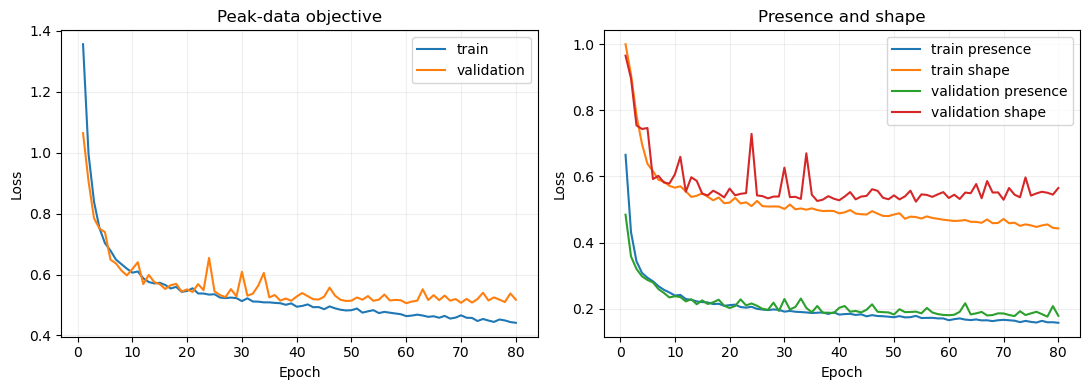

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for part in ("train", "validation"):
    epochs = np.arange(1, len(history[part]["total"]) + 1)
    axes[0].plot(epochs, history[part]["total"], label=part)
    axes[1].plot(epochs, history[part]["presence"], label=f"{part} presence")
    axes[1].plot(epochs, history[part]["shape"], label=f"{part} shape")
axes[0].set(title="Peak-data objective", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Presence and shape", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "peak_training_curves.png", dpi=160)
plt.show()

## 7. Predict physical peak parameters

Each prediction is a candidate for lmfit optimization in the final cell. The threshold is adjustable; the reported FWHM is a separate geometric estimate, while `model_sigma_ev` is the profile parameter. On absent peaks, parameter fields are omitted. The satellite is suppressed if its aromatic/graphitic parent is absent.

In [21]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
assert checkpoint["manifest"] == manifest, "The .nxs source changed after this checkpoint was trained"
assert tuple(checkpoint["component_names"]) == component_names
assert tuple(checkpoint["shape_names"]) == shape_names
model.load_state_dict(checkpoint["state_dict"])
model.eval()

def output_to_arrays(output, threshold=PRESENCE_THRESHOLD):
    raw = {name: value.detach().cpu().numpy() for name, value in output.items()
           if name not in ("mu", "logvar")}
    probability = 1.0 / (1.0 + np.exp(-raw["presence_logits"]))
    selected = probability >= threshold
    selected[:, 5] &= selected[:, 4]  # π–π* requires an aromatic/graphitic parent.
    shape = raw["shape_logits"].argmax(axis=2) + 1
    shape[~selected] = 0
    center_ev = energy_min + raw["center"] * scales["energy_span_ev"]
    fwhm_ev = raw["fwhm"] * scales["fwhm_ev"]
    sigma_ev = raw["sigma"] * scales["sigma_ev"]
    gamma_ev = raw["lorentz_gamma"] * scales["lorentz_gamma_ev"]
    asymmetry = raw["asymmetry_gamma"] * scales["asymmetry_gamma"]
    height = np.expm1(np.clip(raw["log_height"] * np.log1p(scales["height_counts"]), 0, 30))
    area = np.expm1(np.clip(raw["log_area"] * np.log1p(scales["area_counts_ev"]), 0, 30))
    selected_area = np.where(selected, area, 0.0)
    fraction = selected_area / np.maximum(selected_area.sum(axis=1, keepdims=True), 1e-12)
    return {
        "presence_probability": probability, "present": selected, "shape_code": shape,
        "center_ev": center_ev, "fwhm_ev": fwhm_ev, "model_sigma_ev": sigma_ev,
        "lorentz_gamma_ev": gamma_ev, "pseudo_voigt_fraction": raw["pseudo_fraction"],
        "asymmetry_gamma": asymmetry, "height_counts": height,
        "area_counts_ev": selected_area, "area_fraction": fraction,
    }

def predict_peaks(raw_counts, threshold=PRESENCE_THRESHOLD):
    """Predict one spectrum's lmfit candidate parameters on this common energy grid."""
    if not 0.0 <= threshold <= 1.0:
        raise ValueError("threshold must be between 0 and 1")
    x = torch.from_numpy(make_input(raw_counts)).to(DEVICE)
    if len(x) != 1:
        raise ValueError("predict_peaks accepts one spectrum at a time")
    with torch.no_grad():
        physical = output_to_arrays(model(x, sample=False), threshold)
    peaks = []
    for component, name in enumerate(component_names):
        candidate = {
            "component": name,
            "presence_probability": float(physical["presence_probability"][0, component]),
            "present": bool(physical["present"][0, component]),
        }
        if candidate["present"]:
            shape = int(physical["shape_code"][0, component])
            candidate.update({
                "profile": shape_names[shape],
                "center_ev": float(physical["center_ev"][0, component]),
                "fwhm_ev": float(physical["fwhm_ev"][0, component]),
                "model_sigma_ev": float(physical["model_sigma_ev"][0, component]),
                "height_counts": float(physical["height_counts"][0, component]),
                "area_counts_ev": float(physical["area_counts_ev"][0, component]),
                "area_fraction": float(physical["area_fraction"][0, component]),
            })
            if shape == 1:
                candidate["lorentz_gamma_ev"] = float(physical["lorentz_gamma_ev"][0, component])
            elif shape == 2:
                candidate["pseudo_voigt_fraction"] = float(physical["pseudo_voigt_fraction"][0, component])
            elif shape == 3:
                candidate["asymmetry_gamma"] = float(physical["asymmetry_gamma"][0, component])
        peaks.append(candidate)
    return peaks

print("Example held-out scan:")
print(json.dumps(predict_peaks(spectra[indices["test"][0]]), indent=2))

Example held-out scan:
[
  {
    "component": "CC_CH",
    "presence_probability": 0.9999896287918091,
    "present": true,
    "profile": "voigt",
    "center_ev": 284.7840270996094,
    "fwhm_ev": 1.360848307609558,
    "model_sigma_ev": 0.5564761161804199,
    "height_counts": 504.64400130452975,
    "area_counts_ev": 944.5949064855996,
    "area_fraction": 0.9440512835901056,
    "lorentz_gamma_ev": 0.17988859117031097
  },
  {
    "component": "C_O",
    "presence_probability": 0.9844990372657776,
    "present": true,
    "profile": "voigt",
    "center_ev": 286.3494873046875,
    "fwhm_ev": 1.4167016744613647,
    "model_sigma_ev": 0.5925573706626892,
    "height_counts": 34.301965824473044,
    "area_counts_ev": 55.98093394271557,
    "area_fraction": 0.05594871640989442,
    "lorentz_gamma_ev": 0.17166371643543243
  },
  {
    "component": "C_eq_O",
    "presence_probability": 0.1044267863035202,
    "present": false
  },
  {
    "component": "O_C_eq_O",
    "presence_probabili

## 8. Evaluate held-out synthetic scans

Presence metrics use the inference threshold. Shape accuracy is measured for peaks the model and generator both mark present. Numerical errors are measured on correctly detected peaks; presence recall separately exposes missed peaks. Shape-specific errors use the matching true profile and a detected peak. These results measure recovery from this synthetic generator; measured XPS data still need an independent evaluation.

In [22]:
outputs = []
with torch.no_grad():
    for batch_x, _ in loaders["test"]:
        outputs.append(output_to_arrays(model(batch_x.to(DEVICE), sample=False)))
pred = {name: np.concatenate([part[name] for part in outputs], axis=0)
        for name in outputs[0]}
true_present = present[indices["test"]]
pred_present = pred["present"]
true_shape = shape_code[indices["test"]]
matched = true_present & pred_present

def mae(predicted, actual, mask):
    return float(np.mean(np.abs(predicted[mask] - actual[mask]))) if np.any(mask) else None

tp = int(np.sum(pred_present & true_present))
fp = int(np.sum(pred_present & ~true_present))
fn = int(np.sum(~pred_present & true_present))
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
metrics = {
    "scan_count": int(len(indices["test"])),
    "true_peaks": int(true_present.sum()),
    "presence_precision": precision,
    "presence_recall": recall,
    "presence_f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
    "shape_accuracy_on_detected_true_peaks": float(np.mean(pred["shape_code"][matched] == true_shape[matched])) if np.any(matched) else None,
    "center_mae_ev_on_detected_peaks": mae(pred["center_ev"], labels["peak_center_ev"][indices["test"]], matched),
    "fwhm_mae_ev_on_detected_peaks": mae(pred["fwhm_ev"], labels["peak_fwhm_ev"][indices["test"]], matched),
    "model_sigma_mae_ev_on_detected_peaks": mae(pred["model_sigma_ev"], labels["peak_model_sigma_ev"][indices["test"]], matched),
    "lorentz_gamma_mae_ev_on_detected_voigt": mae(pred["lorentz_gamma_ev"], labels["peak_lorentz_gamma_ev"][indices["test"]], matched & (true_shape == 1)),
    "pseudo_fraction_mae_on_detected_pseudo_voigt": mae(pred["pseudo_voigt_fraction"], labels["peak_pseudo_voigt_fraction"][indices["test"]], matched & (true_shape == 2)),
    "asymmetry_gamma_mae_on_detected_doniach": mae(pred["asymmetry_gamma"], labels["peak_asymmetry_gamma"][indices["test"]], matched & (true_shape == 3)),
    "height_mae_counts_on_detected_peaks": mae(pred["height_counts"], labels["peak_height_counts"][indices["test"]], matched),
    "area_mae_counts_ev_on_detected_peaks": mae(pred["area_counts_ev"], labels["peak_area_counts_ev"][indices["test"]], matched),
    "area_fraction_mae_on_detected_peaks": mae(pred["area_fraction"], labels["peak_area_fraction"][indices["test"]], matched),
}
print(json.dumps(metrics, indent=2))

fieldnames = [
    "scan_index", "source_file", "source_row", "case_id", "family", "background_kind", "component",
    "true_present", "predicted_present", "presence_probability", "true_shape", "predicted_shape",
    "true_center_ev", "predicted_center_ev", "true_fwhm_ev", "predicted_fwhm_ev",
    "true_model_sigma_ev", "predicted_model_sigma_ev", "true_height_counts", "predicted_height_counts",
    "true_area_counts_ev", "predicted_area_counts_ev", "true_area_fraction", "predicted_area_fraction",
    "true_lorentz_gamma_ev", "predicted_lorentz_gamma_ev",
    "true_pseudo_voigt_fraction", "predicted_pseudo_voigt_fraction",
    "true_asymmetry_gamma", "predicted_asymmetry_gamma",
]
with (OUTPUT_DIR / "test_peak_predictions.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=fieldnames)
    writer.writeheader()
    for local, scan_index in enumerate(indices["test"]):
        for component, component_name in enumerate(component_names):
            def value(name):
                result = labels[name][scan_index, component]
                return "" if not np.isfinite(result) else float(result)
            writer.writerow({
                "scan_index": int(scan_index),
                "source_file": labels["source_file"][scan_index],
                "source_row": int(labels["source_row"][scan_index]),
                "case_id": int(labels["case_id"][scan_index]),
                "family": labels["family"][scan_index],
                "background_kind": labels["background_kind"][scan_index],
                "component": component_name,
                "true_present": bool(true_present[local, component]),
                "predicted_present": bool(pred_present[local, component]),
                "presence_probability": float(pred["presence_probability"][local, component]),
                "true_shape": shape_names[int(true_shape[local, component])],
                "predicted_shape": shape_names[int(pred["shape_code"][local, component])],
                "true_center_ev": value("peak_center_ev"),
                "predicted_center_ev": float(pred["center_ev"][local, component]) if pred_present[local, component] else "",
                "true_fwhm_ev": value("peak_fwhm_ev"),
                "predicted_fwhm_ev": float(pred["fwhm_ev"][local, component]) if pred_present[local, component] else "",
                "true_model_sigma_ev": value("peak_model_sigma_ev"),
                "predicted_model_sigma_ev": float(pred["model_sigma_ev"][local, component]) if pred_present[local, component] else "",
                "true_height_counts": value("peak_height_counts"),
                "predicted_height_counts": float(pred["height_counts"][local, component]) if pred_present[local, component] else "",
                "true_area_counts_ev": value("peak_area_counts_ev"),
                "predicted_area_counts_ev": float(pred["area_counts_ev"][local, component]) if pred_present[local, component] else "",
                "true_area_fraction": value("peak_area_fraction"),
                "predicted_area_fraction": float(pred["area_fraction"][local, component]) if pred_present[local, component] else "",
                "true_lorentz_gamma_ev": value("peak_lorentz_gamma_ev"),
                "predicted_lorentz_gamma_ev": float(pred["lorentz_gamma_ev"][local, component]) if pred["shape_code"][local, component] == 1 else "",
                "true_pseudo_voigt_fraction": value("peak_pseudo_voigt_fraction"),
                "predicted_pseudo_voigt_fraction": float(pred["pseudo_voigt_fraction"][local, component]) if pred["shape_code"][local, component] == 2 else "",
                "true_asymmetry_gamma": value("peak_asymmetry_gamma"),
                "predicted_asymmetry_gamma": float(pred["asymmetry_gamma"][local, component]) if pred["shape_code"][local, component] == 3 else "",
            })

{
  "scan_count": 5000,
  "true_peaks": 15705,
  "presence_precision": 0.9573592790910278,
  "presence_recall": 0.9335243553008596,
  "presence_f1": 0.9452915954737419,
  "shape_accuracy_on_detected_true_peaks": 0.7139349294045426,
  "center_mae_ev_on_detected_peaks": 0.1388327181339264,
  "fwhm_mae_ev_on_detected_peaks": 0.09886886179447174,
  "model_sigma_mae_ev_on_detected_peaks": 0.07096509635448456,
  "lorentz_gamma_mae_ev_on_detected_voigt": 0.022465812042355537,
  "pseudo_fraction_mae_on_detected_pseudo_voigt": 0.06826677173376083,
  "asymmetry_gamma_mae_on_detected_doniach": 0.015119777992367744,
  "height_mae_counts_on_detected_peaks": 3143.9618483612526,
  "area_mae_counts_ev_on_detected_peaks": 4753.297454954428,
  "area_fraction_mae_on_detected_peaks": 0.03897575267478757
}


## 9. Map success and failure across the held-out set

The overall score can hide weak components and difficult scans. The next cell reports detection, shape, center, width, and area-fraction errors by chemical family, background, peak count, count level, component, and true profile. Count-level bins come from training scans. It also ranks held-out cases and plots representative easy and hard cases. These are synthetic test results, not measured-sample validation.


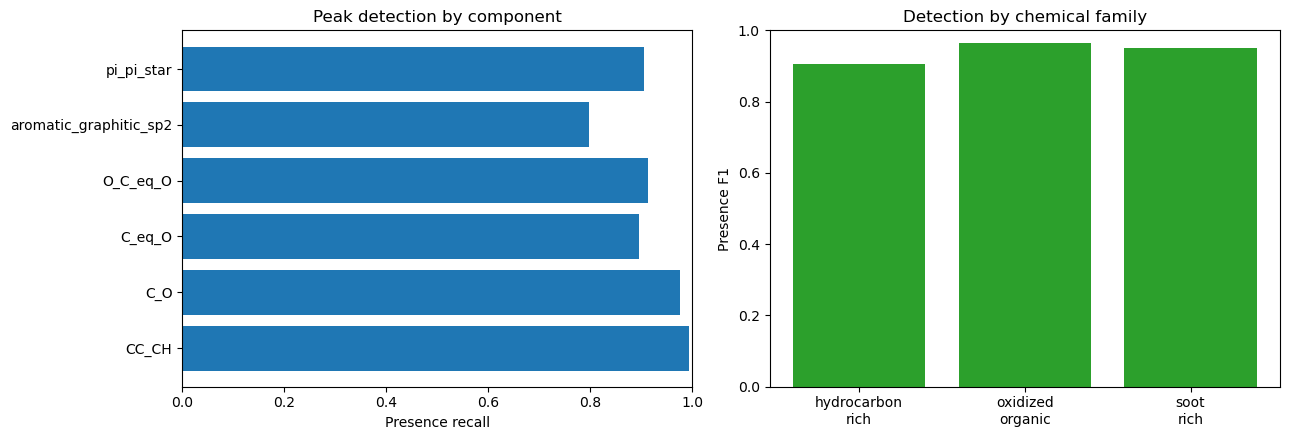

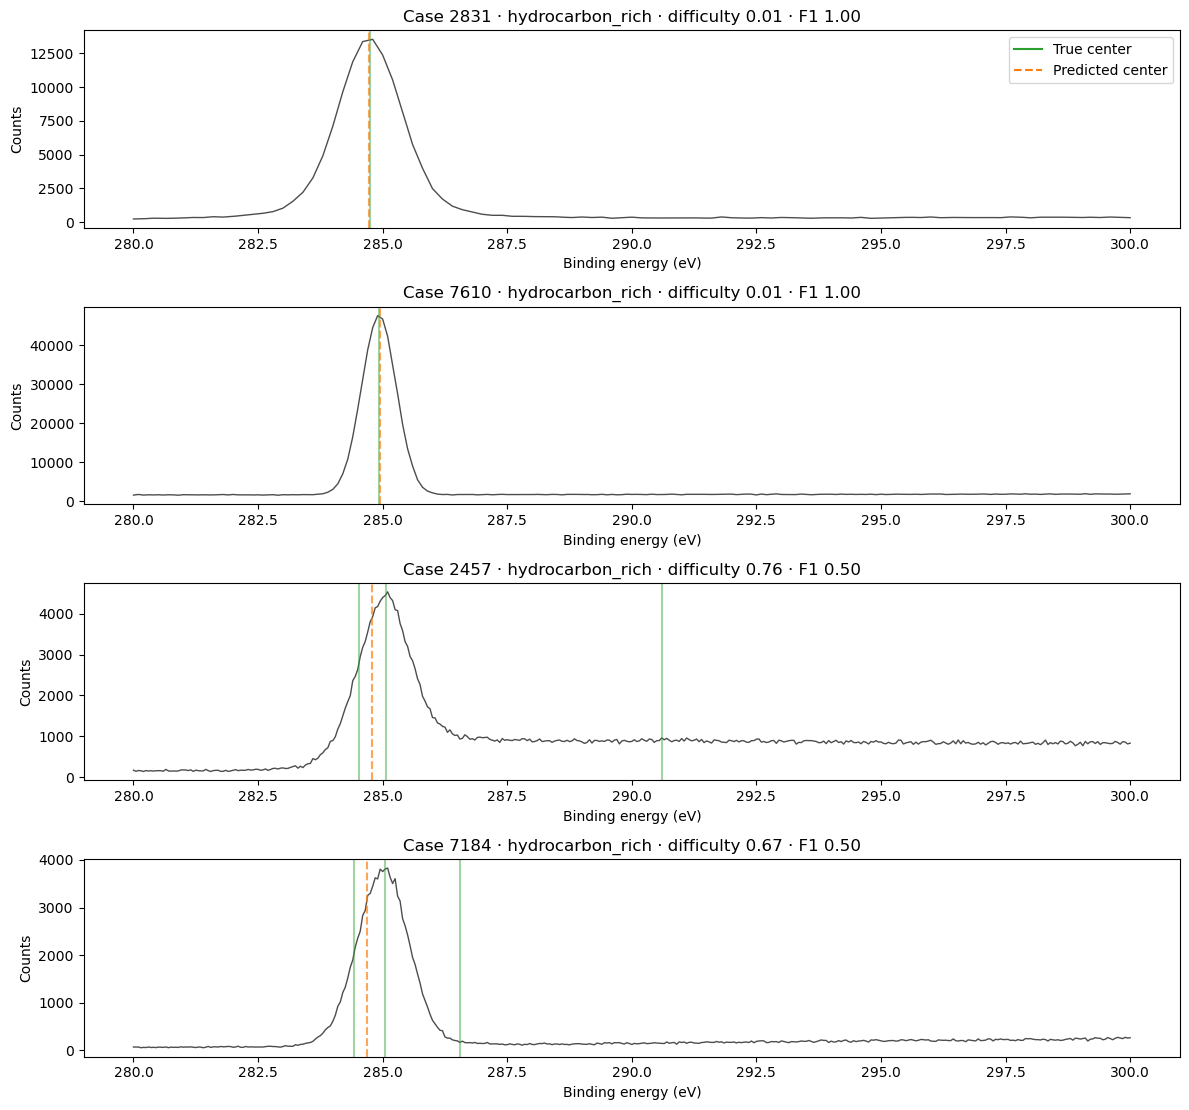

Easiest cases: [(2831, 0.01), (7610, 0.01), (5977, 0.01), (1129, 0.01), (3102, 0.01)]
Hardest cases: [(4302, 0.57), (7097, 0.61), (236, 0.62), (7184, 0.67), (2457, 0.76)]
Saved /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/test_morphology_breakdown.csv, /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/test_case_difficulty.csv, /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/test_morphology_overview.png, and /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/test_easy_hard_examples.png


In [23]:
test_idx = indices["test"]
test_case = labels["case_id"][test_idx]
true_center = labels["peak_center_ev"][test_idx]
true_fwhm = labels["peak_fwhm_ev"][test_idx]
true_fraction = labels["peak_area_fraction"][test_idx]

def group_metrics(slot_mask, include_precision=True):
    slot_mask = np.asarray(slot_mask, dtype=bool)
    group_true = true_present & slot_mask
    group_pred = pred_present & slot_mask
    group_matched = group_true & group_pred
    tp_group = int(group_matched.sum())
    fp_group = int((group_pred & ~group_true).sum())
    fn_group = int((group_true & ~group_pred).sum())
    group_precision = tp_group / (tp_group + fp_group) if tp_group + fp_group else 0.0
    group_recall = tp_group / (tp_group + fn_group) if tp_group + fn_group else 0.0
    return {
        "true_peaks": int(group_true.sum()), "detected_peaks": tp_group,
        "false_positives": fp_group if include_precision else None,
        "false_negatives": fn_group,
        "presence_precision": group_precision if include_precision else None,
        "presence_recall": group_recall,
        "presence_f1": ((2 * group_precision * group_recall / (group_precision + group_recall)
                         if group_precision + group_recall else 0.0)
                        if include_precision and (group_true.any() or group_pred.any()) else None),
        "shape_accuracy": (float(np.mean(pred["shape_code"][group_matched] == true_shape[group_matched]))
                           if tp_group else None),
        "center_mae_ev": mae(pred["center_ev"], true_center, group_matched),
        "fwhm_mae_ev": mae(pred["fwhm_ev"], true_fwhm, group_matched),
        "area_fraction_mae": mae(pred["area_fraction"], true_fraction, group_matched),
    }

breakdown = []
def add_group(segment, name, row_mask):
    slot_mask = np.broadcast_to(np.asarray(row_mask)[:, None], true_present.shape)
    breakdown.append({"segment": segment, "group": str(name),
                      "scans": int(np.sum(row_mask)),
                      "cases": int(np.unique(test_case[row_mask]).size),
                      **group_metrics(slot_mask)})

for family in np.unique(labels["family"][test_idx]):
    add_group("family", family, labels["family"][test_idx] == family)
for background in np.unique(labels["background_kind"][test_idx]):
    add_group("background", background, labels["background_kind"][test_idx] == background)
for count in range(1, n_components + 1):
    add_group("true_peak_count", count, true_present.sum(axis=1) == count)
train_max = spectra[indices["train"]].max(axis=1)
count_edges = np.quantile(train_max, [1 / 3, 2 / 3])
test_max = spectra[test_idx].max(axis=1)
count_bins = np.searchsorted(count_edges, test_max, side="right")
for tier, name in enumerate(("low", "middle", "high")):
    add_group("count_level", name, count_bins == tier)
for component, name in enumerate(component_names):
    slot_mask = np.zeros_like(true_present)
    slot_mask[:, component] = True
    breakdown.append({"segment": "component", "group": name,
                      "scans": len(test_idx), "cases": len(np.unique(test_case)),
                      **group_metrics(slot_mask)})
for shape in range(1, len(shape_names)):
    slot_mask = true_shape == shape
    breakdown.append({"segment": "true_profile", "group": shape_names[shape],
                      "scans": int(np.sum(slot_mask.any(axis=1))),
                      "cases": int(np.unique(test_case[slot_mask.any(axis=1)]).size),
                      **group_metrics(slot_mask, include_precision=False)})

breakdown_path = OUTPUT_DIR / "test_morphology_breakdown.csv"
with breakdown_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(breakdown[0]))
    writer.writeheader()
    writer.writerows(breakdown)

# Rank by case, keeping all repeated acquisitions together.
case_rows = []
for case_id in np.unique(test_case):
    rows = np.flatnonzero(test_case == case_id)
    slot_mask = np.zeros_like(true_present)
    slot_mask[rows] = True
    result = group_metrics(slot_mask)
    f1 = result["presence_f1"] or 0.0
    center_error = result["center_mae_ev"] if result["center_mae_ev"] is not None else 1.0
    center_penalty = min(center_error / 0.5, 1.0)
    shape_penalty = 1.0 - (result["shape_accuracy"] or 0.0)
    difficulty = 1.0 - f1 + 0.25 * center_penalty + 0.15 * shape_penalty
    case_rows.append({"case_id": int(case_id),
                      "source_file": labels["source_file"][test_idx[rows[0]]],
                      "family": labels["family"][test_idx[rows[0]]],
                      "background": labels["background_kind"][test_idx[rows[0]]],
                      "replicates": len(rows), "true_peak_count": int(true_present[rows[0]].sum()),
                      "median_max_counts": float(np.median(test_max[rows])),
                      "difficulty_score": float(difficulty), **result})
case_rows.sort(key=lambda row: row["difficulty_score"])
case_path = OUTPUT_DIR / "test_case_difficulty.csv"
with case_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(case_rows[0]))
    writer.writeheader()
    writer.writerows(case_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
component_rows = [row for row in breakdown if row["segment"] == "component"]
axes[0].barh([row["group"] for row in component_rows],
             [row["presence_recall"] for row in component_rows], color="tab:blue")
axes[0].set(xlim=(0, 1), xlabel="Presence recall", title="Peak detection by component")
family_rows = [row for row in breakdown if row["segment"] == "family"]
axes[1].bar([row["group"].replace("_", "\n") for row in family_rows],
            [row["presence_f1"] or 0 for row in family_rows], color="tab:green")
axes[1].set(ylim=(0, 1), ylabel="Presence F1", title="Detection by chemical family")
fig.tight_layout()
overview_path = OUTPUT_DIR / "test_morphology_overview.png"
fig.savefig(overview_path, dpi=170)
plt.show()

selected_cases = []
for case in case_rows[:2] + list(reversed(case_rows[-2:])):
    if case["case_id"] not in {item["case_id"] for item in selected_cases}:
        selected_cases.append(case)
fig, axes = plt.subplots(len(selected_cases), 1, figsize=(12, 2.8 * len(selected_cases)), squeeze=False)
for ax, case in zip(axes[:, 0], selected_cases):
    local = int(np.flatnonzero(test_case == case["case_id"])[0])
    scan_index = int(test_idx[local])
    ax.plot(energy_ev, spectra[scan_index], color="0.3", lw=1)
    for component in range(n_components):
        if true_present[local, component]:
            ax.axvline(true_center[local, component], color="tab:green", alpha=0.45)
        if pred_present[local, component]:
            ax.axvline(pred["center_ev"][local, component], color="tab:orange", ls="--", alpha=0.7)
    ax.set(title=f"Case {case['case_id']} · {case['family']} · difficulty {case['difficulty_score']:.2f} · F1 {case['presence_f1']:.2f}",
           xlabel="Binding energy (eV)", ylabel="Counts")
axes[0, 0].plot([], [], color="tab:green", label="True center")
axes[0, 0].plot([], [], color="tab:orange", ls="--", label="Predicted center")
axes[0, 0].legend()
fig.tight_layout()
case_plot_path = OUTPUT_DIR / "test_easy_hard_examples.png"
fig.savefig(case_plot_path, dpi=170)
plt.show()
print("Easiest cases:", [(row["case_id"], round(row["difficulty_score"], 2)) for row in case_rows[:5]])
print("Hardest cases:", [(row["case_id"], round(row["difficulty_score"], 2)) for row in case_rows[-5:]])
print(f"Saved {breakdown_path}, {case_path}, {overview_path}, and {case_plot_path}")


## 10. Inspect a few predictions and save the summary

The spectrum below is shown only as input context; the model has no output spectrum. Vertical markers compare true and predicted component centers.

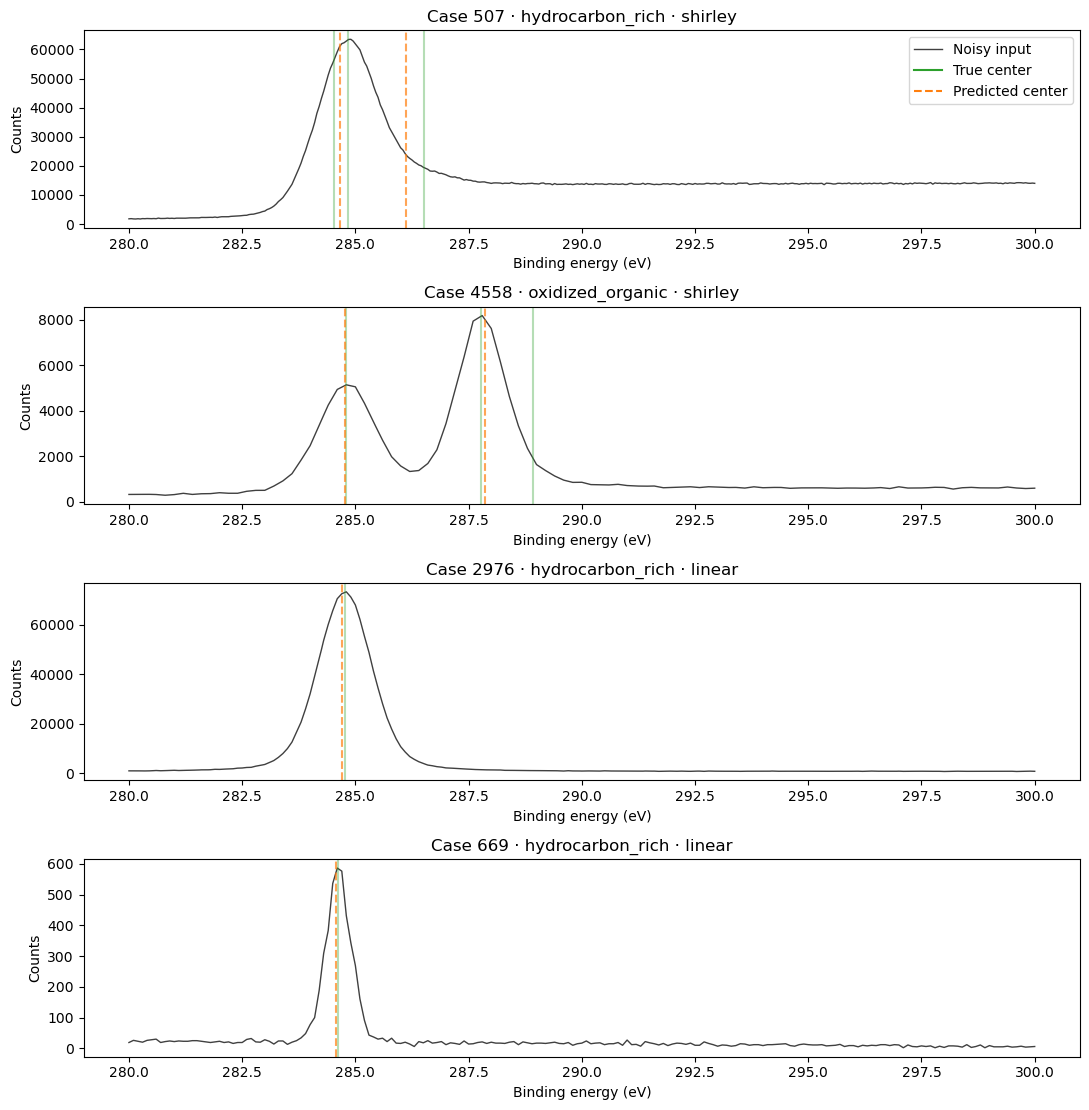

Saved outputs in /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae


In [24]:
example_count = min(4, len(indices["test"]))
example_local = np.random.default_rng(SEED + 100).choice(len(indices["test"]), example_count, replace=False)
fig, axes = plt.subplots(example_count, 1, figsize=(11, 2.8 * example_count), squeeze=False)
for ax, local in zip(axes[:, 0], example_local):
    scan_index = indices["test"][local]
    ax.plot(energy_ev, spectra[scan_index], color="0.25", lw=1, label="Noisy input")
    for component in range(n_components):
        if true_present[local, component]:
            ax.axvline(labels["peak_center_ev"][scan_index, component], color="tab:green", alpha=0.35)
        if pred_present[local, component]:
            ax.axvline(pred["center_ev"][local, component], color="tab:orange", alpha=0.7, ls="--")
    ax.set(title=f"Case {labels['case_id'][scan_index]} · {labels['family'][scan_index]} · {labels['background_kind'][scan_index]}",
           xlabel="Binding energy (eV)", ylabel="Counts")
axes[0, 0].plot([], [], color="tab:green", label="True center")
axes[0, 0].plot([], [], color="tab:orange", ls="--", label="Predicted center")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_peak_examples.png", dpi=160)
plt.show()

summary = {
    "model_kind": "supervised_variational_peak_parameter_encoder_decoder",
    "source": manifest,
    "best_epoch": best_epoch,
    "best_validation_peak_loss": best_val,
    "presence_threshold": PRESENCE_THRESHOLD,
    "latent_dim": LATENT_DIM,
    "test_metrics": metrics,
    "checkpoint": str(CHECKPOINT_PATH),
    "prediction_csv": str(OUTPUT_DIR / "test_peak_predictions.csv"),
    "morphology_breakdown_csv": str(breakdown_path),
    "case_difficulty_csv": str(case_path),
    "morphology_overview_plot": str(overview_path),
    "easy_hard_examples_plot": str(case_plot_path),
}
with (OUTPUT_DIR / "test_summary.json").open("w") as handle:
    json.dump(summary, handle, indent=2)
print(f"Saved outputs in {OUTPUT_DIR}")

## 11. Automatic lmfit refinement

`peak_fitting.fit_predicted_peaks` accepts a list of predicted peaks of any length. Each record needs a center and FWHM (or sigma); it can also supply area, height, and a profile name. The adapter builds lmfit models, estimates missing starting values, compares linear, Shirley, and Tougaard backgrounds by BIC, and returns fitted curves and peak properties. If a predictor does not output profile type, use `"profile": "auto"` (or omit it); the adapter compares its built-in Gaussian, Voigt, pseudo-Voigt, and broadened Doniach options. The model itself still has six chemically named output slots because of its training labels. The adapter does not prove that these four peak shapes or three backgrounds describe every measured material.

Minimal input from another predictor: `[{"center_ev": 284.8, "fwhm_ev": 1.0, "area_counts_ev": 5000}]`. Call `fit_predicted_peaks(energy_ev, counts, predictions)`; no hand-written lmfit formula is needed for these supported shapes.


Case 30, scan 55
Selected background: shirley; BIC: 45.29; success: True
[[Fit Statistics]]
    # fitting method   = least_squares
    # function evals   = 140
    # data points      = 401
    # variables        = 9
    chi-square         = 392.437524
    reduced chi-square = 1.00111613
    Akaike info crit   = 9.34478456
    Bayesian info crit = 45.2904374
[[Variables]]
    p0_amplitude:      835.412893 +/- 12.4331599 (1.49%) (init = 959.8568)
    p0_center:         284.658312 +/- 0.01040506 (0.00%) (init = 284.784)
    p0_sigma:          0.46873446 +/- 0.00940604 (2.01%) (init = 0.5564761)
    p0_gamma:          0.1798886 (fixed)
    p0_fwhm:           1.30874088 +/- 0.02189881 (1.67%) == '1.0692*p0_gamma+sqrt(0.8664*p0_gamma**2+5.545083*p0_sigma**2)'
    p0_height:         536.629407 +/- 6.39997617 (1.19%) == '(p0_amplitude/(max(1e-15, p0_sigma*sqrt(2*pi))))*real(wofz((1j*p0_gamma)/(max(1e-15, p0_sigma*sqrt(2)))))'
    p1_amplitude:      40.8648148 +/- 11.4822661 (28.10%) (init = 56

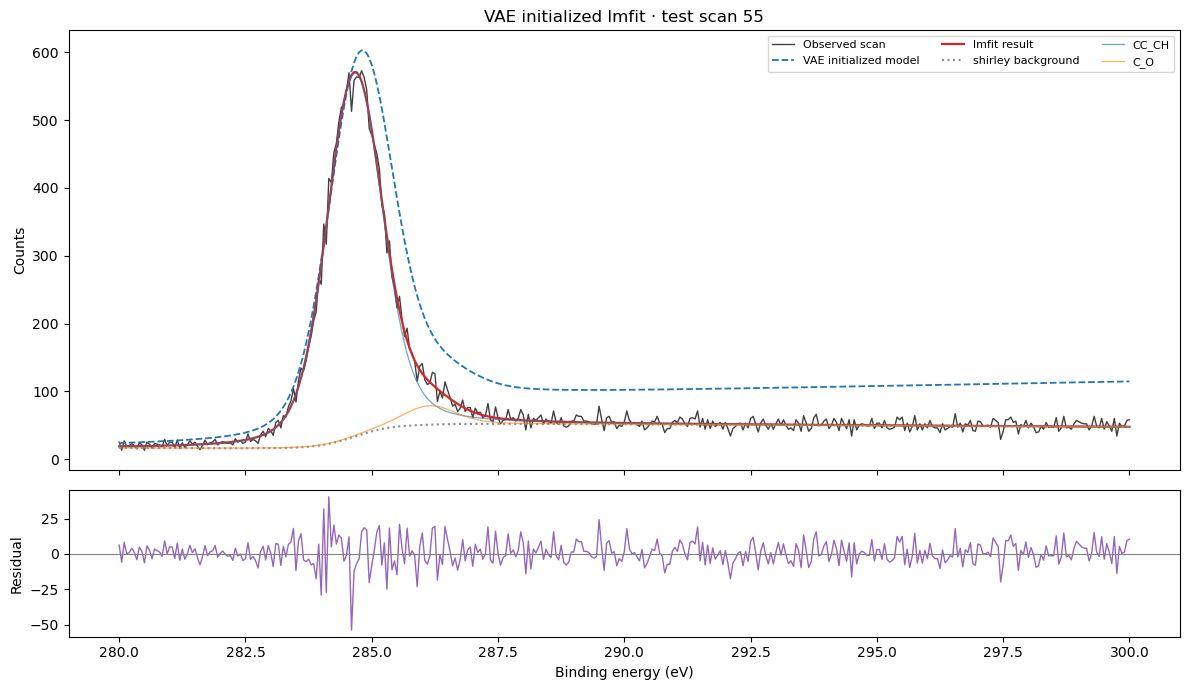

Saved /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/lmfit_scan_00055.csv, /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/lmfit_scan_00055.json, and /home/umar/Downloads/VAE_C1s_SESSA-main/outputs/c1s_nexus_peak_vae/lmfit_scan_00055.png


In [25]:
# Fit one held-out scan using the reusable adapter.
# Any predictor can call fit_predicted_peaks(energy, counts, peak_records).
from peak_fitting import fit_predicted_peaks
from lmfit import fit_report

FIT_SCAN_INDEX = int(indices["test"][0])
FIT_PRESENCE_THRESHOLD = PRESENCE_THRESHOLD
assert FIT_SCAN_INDEX in set(indices["test"].tolist()), "Choose a held-out test scan"
x_fit = np.asarray(energy_ev, dtype=np.float64)
y_fit = np.asarray(spectra[FIT_SCAN_INDEX], dtype=np.float64)
fit_guesses = predict_peaks(y_fit, threshold=FIT_PRESENCE_THRESHOLD)
fit = fit_predicted_peaks(x_fit, y_fit, fit_guesses)
print(f"Case {labels['case_id'][FIT_SCAN_INDEX]}, scan {FIT_SCAN_INDEX}")
print(f"Selected background: {fit.background_kind}; BIC: {fit.bic:.2f}; success: {fit.success}")
print(fit_report(fit.fit_result))

fit_csv_path = OUTPUT_DIR / f"lmfit_scan_{FIT_SCAN_INDEX:05d}.csv"
curve_columns = {
    "binding_energy_ev": fit.energy_ev,
    "observed_counts": fit.observed_counts,
    "vae_initialized_counts": fit.initial_counts,
    "lmfit_fitted_counts": fit.fitted_counts,
    "fitted_background_counts": fit.background_counts,
    "residual_counts": fit.observed_counts - fit.fitted_counts,
}
for component, curve in fit.component_counts.items():
    curve_columns[f"{component}_counts"] = curve
with fit_csv_path.open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(curve_columns)
    writer.writerows(zip(*curve_columns.values()))

fit_summary_path = OUTPUT_DIR / f"lmfit_scan_{FIT_SCAN_INDEX:05d}.json"
with fit_summary_path.open("w") as handle:
    json.dump({
        "scan_index": FIT_SCAN_INDEX,
        "source_file": labels["source_file"][FIT_SCAN_INDEX],
        "source_row": int(labels["source_row"][FIT_SCAN_INDEX]),
        "case_id": int(labels["case_id"][FIT_SCAN_INDEX]),
        "selected_background": fit.background_kind,
        "bic": fit.bic, "success": fit.success,
        "vae_initial_peaks": [peak for peak in fit_guesses if peak["present"]],
        "lmfit_peaks": fit.peaks,
    }, handle, indent=2)

fig, (ax, residual_ax) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
ax.plot(x_fit, y_fit, color="0.25", lw=1, label="Observed scan")
ax.plot(x_fit, fit.initial_counts, color="tab:blue", ls="--", lw=1.3, label="VAE initialized model")
ax.plot(x_fit, fit.fitted_counts, color="tab:red", lw=1.6, label="lmfit result")
ax.plot(x_fit, fit.background_counts, color="0.55", ls=":", label=f"{fit.background_kind} background")
for component, curve in fit.component_counts.items():
    ax.plot(x_fit, curve + fit.background_counts, lw=0.9, alpha=0.65, label=component)
ax.set(ylabel="Counts", title=f"VAE initialized lmfit · test scan {FIT_SCAN_INDEX}")
ax.legend(ncol=3, fontsize=8)
residual_ax.plot(x_fit, y_fit - fit.fitted_counts, color="tab:purple", lw=1)
residual_ax.axhline(0, color="0.5", lw=0.8)
residual_ax.set(xlabel="Binding energy (eV)", ylabel="Residual")
fig.tight_layout()
fit_plot_path = OUTPUT_DIR / f"lmfit_scan_{FIT_SCAN_INDEX:05d}.png"
fig.savefig(fit_plot_path, dpi=180)
plt.show()
print(f"Saved {fit_csv_path}, {fit_summary_path}, and {fit_plot_path}")
